# 📚 Libraries 

In [43]:
import pandas as pd
import numpy as np
import random

import math

from PIL import Image
import matplotlib.pyplot as plt
import plotly.express as px

from tqdm.auto import tqdm
from pathlib import Path
import os

# EDA 🔎

## 🧾

In [3]:
path = r"C:\Users\malik\Documents\AI\my_prjects\fetal_anomalies\fetal_vision\data\raw\FETAL_PLANES_DB_data.csv"
df_original = pd.read_csv(path, sep=";")

df_original.head()

,Image_name,Patient_num,Plane,Brain_plane,Operator,US_Machine,Train
0,Patient00001_Plane1_1_of_15,1,Other,Not A Brain,Other,Aloka,1
1,Patient00001_Plane1_2_of_15,1,Other,Not A Brain,Other,Aloka,1
2,Patient00001_Plane1_3_of_15,1,Other,Not A Brain,Other,Aloka,1
3,Patient00001_Plane1_4_of_15,1,Other,Not A Brain,Other,Aloka,1
4,Patient00001_Plane1_5_of_15,1,Other,Not A Brain,Other,Aloka,1


In [6]:
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 12400 entries, 0 to 12399
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Image_name   12400 non-null  str  
 1   Patient_num  12400 non-null  int64
 2   Plane        12400 non-null  str  
 3   Brain_plane  12400 non-null  str  
 4   Operator     12400 non-null  str  
 5   US_Machine   12400 non-null  str  
 6   Train        12400 non-null  int64
dtypes: int64(2), str(5)
memory usage: 678.3 KB


In [7]:
df_original.Plane.value_counts()

Plane
Other              4213
Fetal brain        3092
Fetal thorax       1718
Maternal cervix    1626
Fetal femur        1040
Fetal abdomen       711
Name: count, dtype: int64

In [9]:
fig = px.pie(df_original, names="Plane", title="")
fig.show()

## 🖼️

In [ ]:
# inspect a sample 
def inspect_images(image_paths, n=6, seed=42):
    rng = random.Random(seed)
    samples = rng.sample(list(image_paths), min(n, len(image_paths)))

    stats = []

    ncols = 3
    nrows = int(np.ceil(len(samples) / ncols))

    plt.figure(figsize=(15, 4 * nrows))

    for i, path in enumerate(samples):
        img = Image.open(path)
        img_np = np.array(img)

        # Channels
        if img_np.ndim == 2:
            channels = "Grayscale"
        else:
            channels = img_np.shape[-1]

        # Statistics
        stats.append({
            "image": path.name,
            "shape": img_np.shape,
            "dtype": str(img_np.dtype),
            "min": img_np.min(),
            "max": img_np.max(),
            "mean": round(img_np.mean(), 2),
            "std": round(img_np.std(), 2),
            "channels": channels
        })

        plt.subplot(nrows, ncols, i + 1)

        if img_np.ndim == 2:
            plt.imshow(img_np, cmap="gray")
        else:
            plt.imshow(img_np)

        plt.title(
            f"{path.name}\n"
            f"{img_np.shape} | {channels}",
            fontsize=8
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

    return pd.DataFrame(stats)

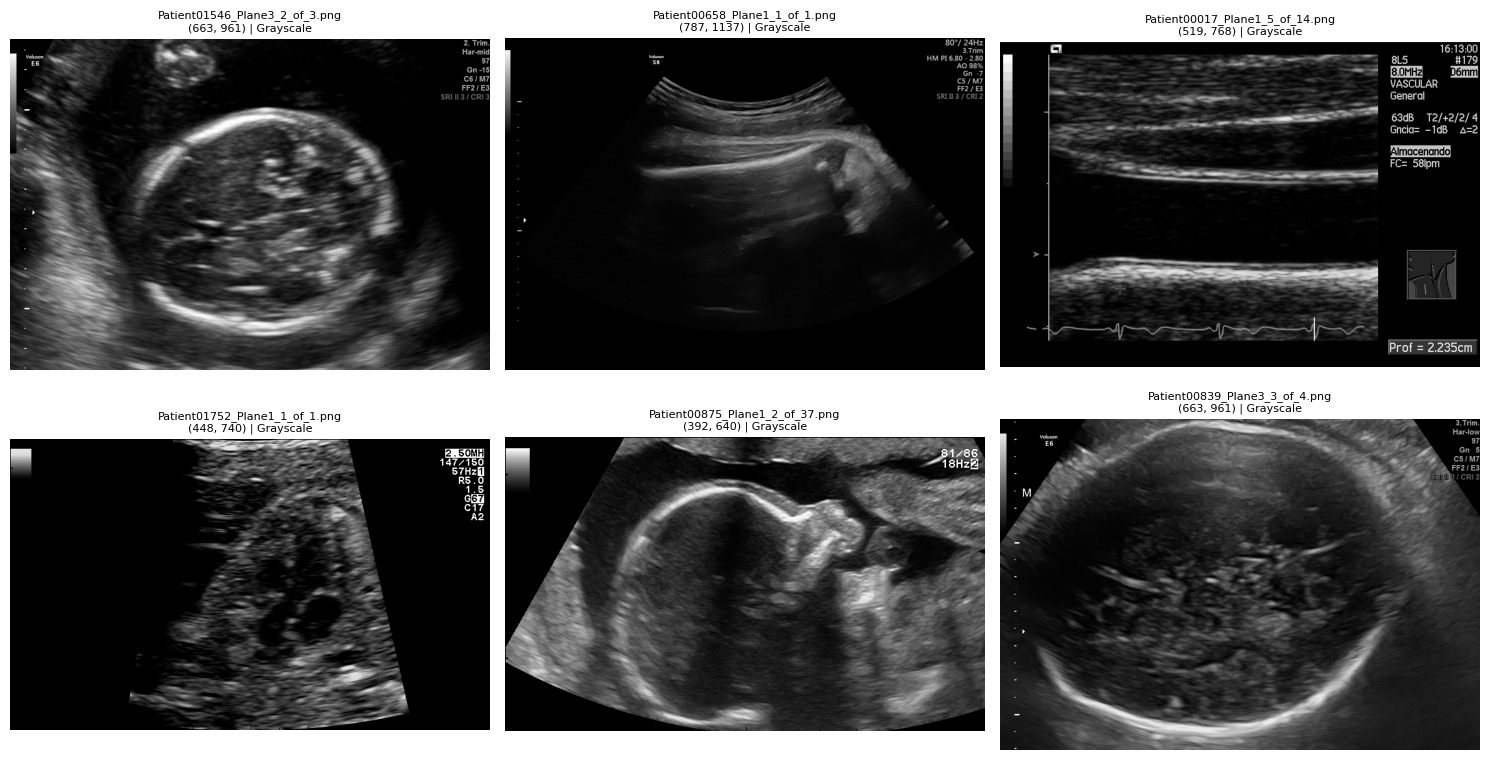

,image,shape,dtype,min,max,mean,std,channels
0,Patient01546_Plane3_2_of_3.png,"(663, 961)",uint8,0,255,47.34,48.40,Grayscale
1,Patient00658_Plane1_1_of_1.png,"(787, 1137)",uint8,0,255,13.65,29.13,Grayscale
2,Patient00017_Plane1_5_of_14.png,"(519, 768)",uint8,0,255,27.90,47.18,Grayscale
3,Patient01752_Plane1_1_of_1.png,"(448, 740)",uint8,0,250,22.37,40.93,Grayscale
4,Patient00875_Plane1_2_of_37.png,"(392, 640)",uint8,0,251,58.18,48.39,Grayscale
5,Patient00839_Plane3_3_of_4.png,"(663, 961)",uint8,0,255,49.64,40.53,Grayscale


In [14]:
image_dir = Path(
    r"C:\Users\malik\Documents\AI\my_prjects\fetal_anomalies\fetal_vision\data\raw\Images")
image_paths = list(image_dir.glob("*"))

sample_stats = inspect_images(image_paths, n=6)
sample_stats

In [16]:
# Let's go over all images et get infos (height, width, PIL Mode, mean/std, dtype...)

def build_image_info(image_paths):
    records = []
    errors = []

    for path in tqdm(image_paths, desc="Inspecting images"):
        try:
            with Image.open(path) as img:
                img_np = np.array(img)

                width, height = img.size

                # Number of channels
                if img_np.ndim == 2:
                    channels = 1
                else:
                    channels = img_np.shape[-1]

                records.append({
                    "image_name": path.name,
                    "image_path": str(path),

                    "width": width,
                    "height": height,
                    "aspect_ratio": width / height,

                    "pil_mode": img.mode,
                    "channels": channels,
                    "shape": img_np.shape,
                    "dtype": str(img_np.dtype),

                    "min_pixel": img_np.min(),
                    "max_pixel": img_np.max(),
                    "mean_pixel": img_np.mean(),
                    "std_pixel": img_np.std(),
                })

        except Exception as e:
            errors.append({
                "image_path": str(path),
                "error": str(e)
            })

    image_info = pd.DataFrame(records)
    errors_df = pd.DataFrame(errors)

    return image_info, errors_df

In [17]:
image_info, image_errors = build_image_info(image_paths)

Inspecting images: 100%|██████████| 12400/12400 [01:10<00:00, 175.51it/s]


In [18]:
image_info.head()

,image_name,image_path,width,height,aspect_ratio,pil_mode,channels,shape,dtype,min_pixel,max_pixel,mean_pixel,std_pixel
0,Patient00001_Plane1_10_of_15.png,C:\Users\malik\Documents\AI\my_prjects\fetal_a...,649,382,1.698953,RGBA,4,"(382, 649, 4)",uint8,0,255,80.370090,105.493106
1,Patient00001_Plane1_11_of_15.png,C:\Users\malik\Documents\AI\my_prjects\fetal_a...,645,386,1.670984,RGBA,4,"(386, 645, 4)",uint8,0,255,98.215294,98.501262
2,Patient00001_Plane1_12_of_15.png,C:\Users\malik\Documents\AI\my_prjects\fetal_a...,687,424,1.620283,RGBA,4,"(424, 687, 4)",uint8,0,255,95.621486,101.126645
3,Patient00001_Plane1_13_of_15.png,C:\Users\malik\Documents\AI\my_prjects\fetal_a...,688,425,1.618824,RGBA,4,"(425, 688, 4)",uint8,0,255,89.320307,102.783126
4,Patient00001_Plane1_14_of_15.png,C:\Users\malik\Documents\AI\my_prjects\fetal_a...,560,378,1.481481,RGBA,4,"(378, 560, 4)",uint8,0,255,100.789214,97.729081


In [19]:
image_info.shape

(12400, 13)

In [20]:
len(image_errors)

0

In [22]:
image_info["pil_mode"].value_counts()

pil_mode
L       12355
RGBA       45
Name: count, dtype: int64

In [21]:
image_info["channels"].value_counts()

channels
1    12355
4       45
Name: count, dtype: int64

In [40]:
# let's check out those 45 images
rgba_info = image_info[
    (image_info["pil_mode"] == "RGBA") |
    (image_info["channels"] == 4)
].copy()

print(f"Number of RGBA images: {len(rgba_info)}")

rgba_info[
    ["image_name", "width", "height", "aspect_ratio", "pil_mode", "channels"]
].head()

Number of RGBA images: 45


,image_name,width,height,aspect_ratio,pil_mode,channels
0,Patient00001_Plane1_10_of_15.png,649,382,1.698953,RGBA,4
1,Patient00001_Plane1_11_of_15.png,645,386,1.670984,RGBA,4
2,Patient00001_Plane1_12_of_15.png,687,424,1.620283,RGBA,4
3,Patient00001_Plane1_13_of_15.png,688,425,1.618824,RGBA,4
4,Patient00001_Plane1_14_of_15.png,560,378,1.481481,RGBA,4


In [ ]:
def show_image_subset(image_df, images_per_page=15, ncols=5):
    for start in range(0, len(image_df), images_per_page):

        page = image_df.iloc[start:start + images_per_page]

        nrows = math.ceil(len(page) / ncols)

        plt.figure(figsize=(15, 3.5 * nrows))

        for i, (_, row) in enumerate(page.iterrows()):
            path = Path(row["image_path"])

            with Image.open(path) as img:
                img_np = np.array(img)

            plt.subplot(nrows, ncols, i + 1)
            plt.imshow(img_np)

            plt.title(
                f"{row['image_name']}\n"
                f"{row['pil_mode']} | {row['width']}×{row['height']}",
                fontsize=8
            )

            plt.axis("off")

        plt.tight_layout()
        plt.show()

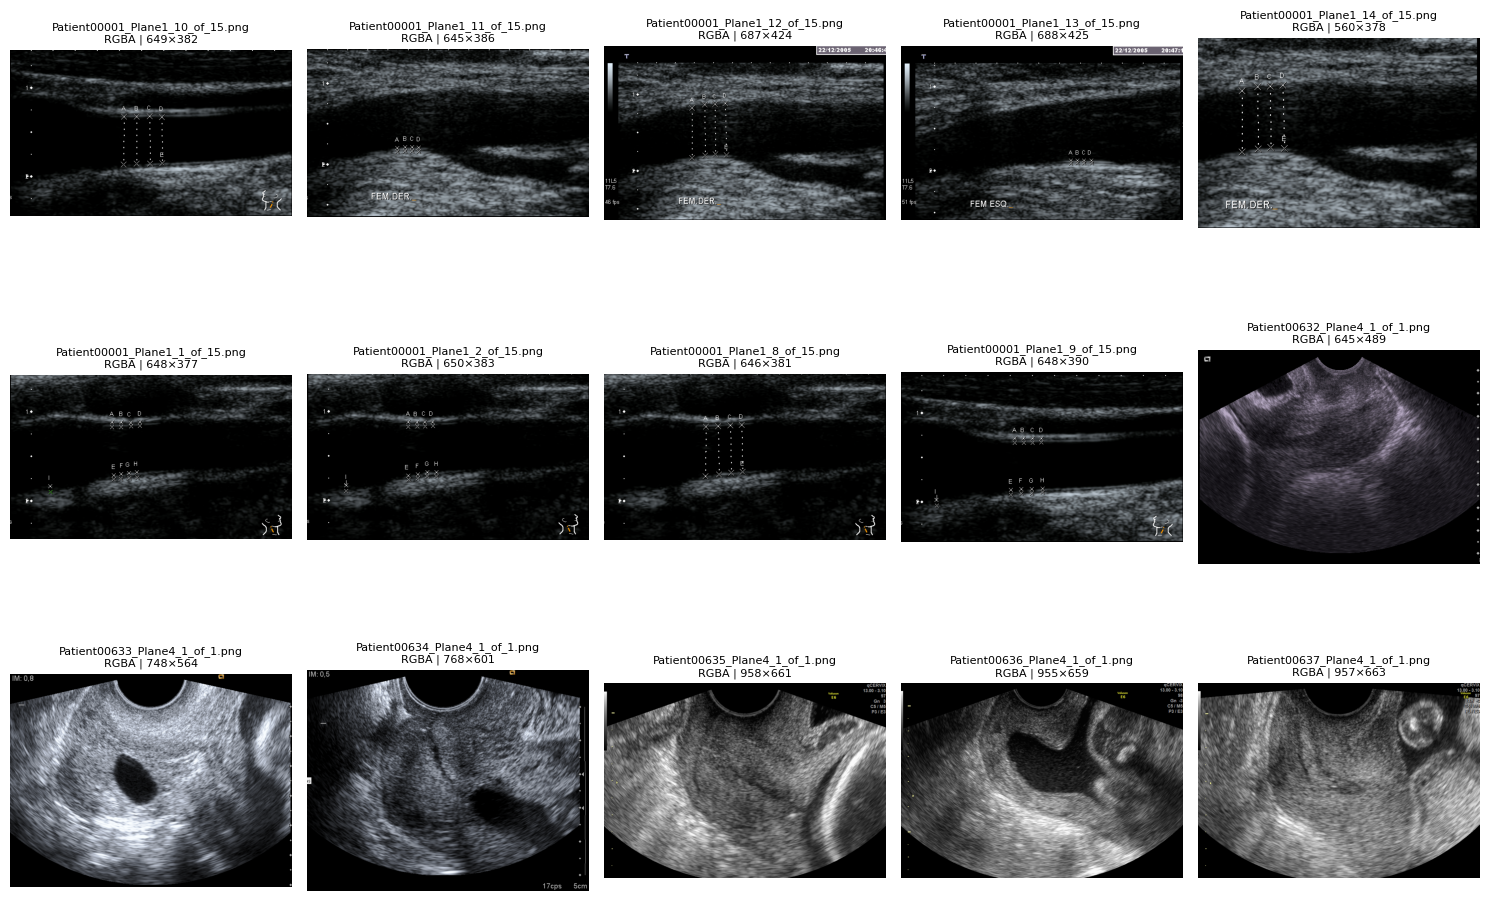

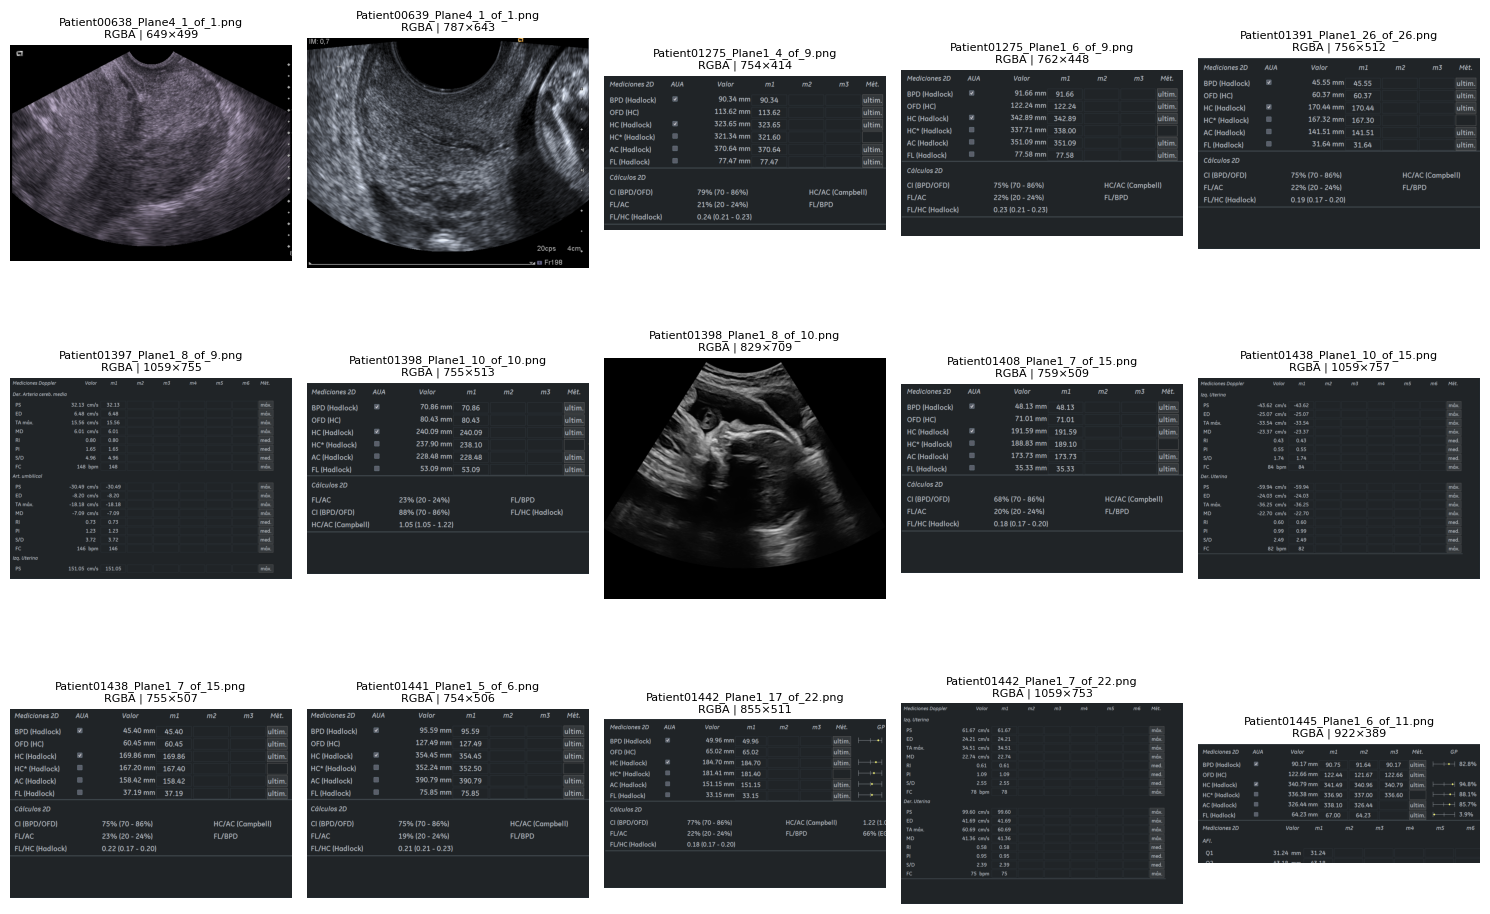

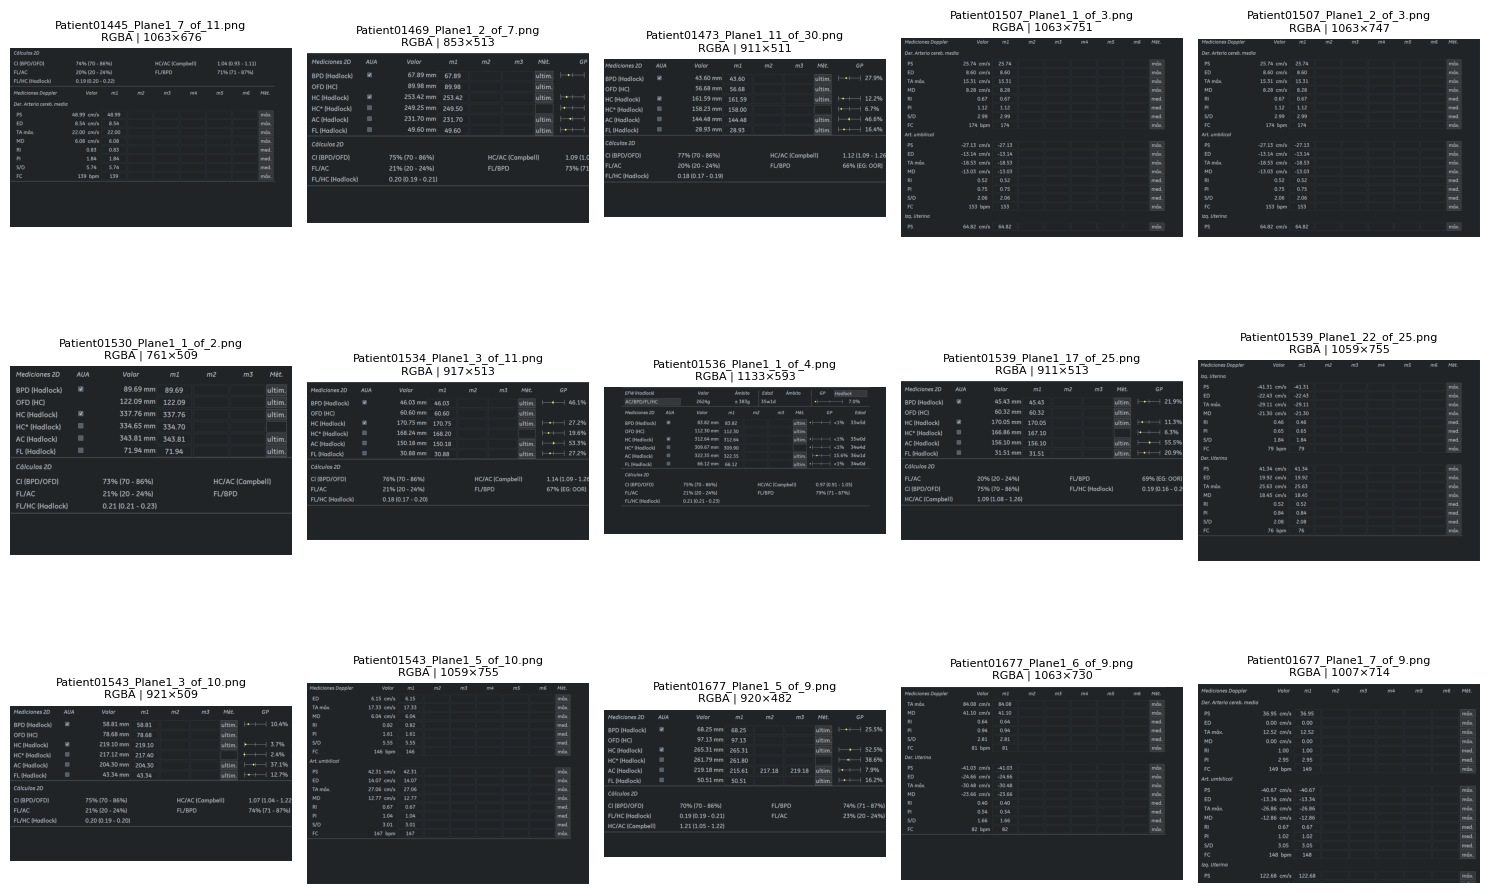

In [42]:
show_image_subset(rgba_info)

In [44]:
def inspect_rgba_images(rgba_df):
    records = []

    for _, row in rgba_df.iterrows():

        path = Path(row["image_path"])

        with Image.open(path) as img:
            arr = np.array(img)

        rgb = arr[:, :, :3]
        alpha = arr[:, :, 3]

        # Difference between RGB channels for every pixel
        rgb_range = rgb.max(axis=2) - rgb.min(axis=2)

        non_gray_pixels = rgb_range > 0

        records.append({
            "image_name": row["image_name"],

            "r_mean": rgb[:, :, 0].mean(),
            "g_mean": rgb[:, :, 1].mean(),
            "b_mean": rgb[:, :, 2].mean(),

            "rgb_identical": bool(np.all(rgb_range == 0)),

            "non_gray_pixels_pct":
                100 * non_gray_pixels.mean(),

            "alpha_min": alpha.min(),
            "alpha_max": alpha.max(),

            "transparent_pixels_pct":
                100 * (alpha < 255).mean(),
        })

    return pd.DataFrame(records)

In [45]:
rgba_diagnostics = inspect_rgba_images(rgba_info)

rgba_diagnostics

,image_name,r_mean,g_mean,b_mean,rgb_identical,non_gray_pixels_pct,alpha_min,alpha_max,transparent_pixels_pct
0,Patient00001_Plane1_10_of_15.png,20.825587,22.569826,23.084947,False,50.084302,255,255,0.0
1,Patient00001_Plane1_11_of_15.png,43.255766,46.533659,48.071752,False,77.081978,255,255,0.0
2,Patient00001_Plane1_12_of_15.png,40.155901,42.925435,44.404610,False,67.203936,255,255,0.0
3,Patient00001_Plane1_13_of_15.png,32.183615,34.506984,35.590629,False,63.338577,255,255,0.0
4,Patient00001_Plane1_14_of_15.png,46.524112,49.971651,51.661092,False,78.568594,255,255,0.0
5,Patient00001_Plane1_1_of_15.png,13.530443,14.854308,14.940290,False,46.157121,255,255,0.0
6,Patient00001_Plane1_2_of_15.png,13.372721,14.669797,14.764258,False,45.639285,255,255,0.0
7,Patient00001_Plane1_8_of_15.png,13.527636,14.841073,14.940254,False,46.117842,255,255,0.0
8,Patient00001_Plane1_9_of_15.png,20.380829,22.086147,22.588003,False,49.019864,255,255,0.0
9,Patient00632_Plane4_1_of_1.png,34.489250,31.846756,37.675798,False,70.249679,255,255,0.0


In [46]:
rgba_diagnostics["rgb_identical"].value_counts()

rgb_identical
False    44
True      1
Name: count, dtype: int64

In [47]:
rgba_diagnostics[
    [
        "non_gray_pixels_pct",
        "transparent_pixels_pct",
        "alpha_min",
        "alpha_max"
    ]
].describe()

,non_gray_pixels_pct,transparent_pixels_pct,alpha_min,alpha_max
count,45.000000,45.0,45.0,45.0
mean,79.650101,0.0,255.0,255.0
std,30.901152,0.0,0.0,0.0
min,0.000000,0.0,255.0,255.0
25%,68.455864,0.0,255.0,255.0
50%,99.647550,0.0,255.0,255.0
75%,99.739602,0.0,255.0,255.0
max,99.815193,0.0,255.0,255.0


**NOTES** ✒️
- Alpha canal is useless  
- 44 out of 45 images are not grayscale **BUT** differences between R,G,B are very small so can we considerate them as colored?  
- So we should go further and set the condition ***rgb_range>0*** less strict  
- Also, plots of those 45 (rgba) planes showes a lot of planes with frames and string infos so we should investigate

In [48]:
def inspect_rgba_images(rgba_df):
    records = []

    for _, row in rgba_df.iterrows():

        path = Path(row["image_path"])

        with Image.open(path) as img:
            arr = np.array(img)

        rgb = arr[:, :, :3]
        alpha = arr[:, :, 3]

        rgb_range = (
            rgb.max(axis=2).astype(int)
            - rgb.min(axis=2).astype(int)
        )

        records.append({
            "image_name": row["image_name"],

            "mean_color_diff": rgb_range.mean(),
            "max_color_diff": rgb_range.max(),

            "pixels_diff_gt_5_pct":
                100 * (rgb_range > 5).mean(),

            "pixels_diff_gt_10_pct":
                100 * (rgb_range > 10).mean(),

            "pixels_diff_gt_20_pct":
                100 * (rgb_range > 20).mean(),

            "pixels_diff_gt_50_pct":
                100 * (rgb_range > 50).mean(),

            "alpha_min": alpha.min(),
            "alpha_max": alpha.max(),
        })

    return pd.DataFrame(records)

In [49]:
rgba_color_analysis = inspect_rgba_images(rgba_info)

rgba_color_analysis[
    [
        "mean_color_diff",
        "max_color_diff",
        "pixels_diff_gt_5_pct",
        "pixels_diff_gt_10_pct",
        "pixels_diff_gt_20_pct",
        "pixels_diff_gt_50_pct",
    ]
].describe()

,mean_color_diff,max_color_diff,pixels_diff_gt_5_pct,pixels_diff_gt_10_pct,pixels_diff_gt_20_pct,pixels_diff_gt_50_pct
count,45.000000,45.000000,45.000000,45.000000,45.000000,45.000000
mean,7.133995,148.488889,71.104302,11.165783,2.301014,1.356633
std,3.397577,65.659460,38.735567,10.295981,1.904655,1.195334
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5.065305,111.000000,39.920472,9.091870,0.282516,0.019239
50%,8.585482,127.000000,99.647049,10.172559,2.192772,1.375047
75%,9.681993,219.000000,99.734425,10.946623,3.948909,2.608515
max,11.191582,247.000000,99.815193,59.260392,7.884382,3.249978


Among 12,400 images, 45 were stored as RGBA. The alpha channel was fully opaque in every case and therefore contained no useful information. Most RGBA images were nearly monochromatic overall, but contained small regions with stronger RGB differences, corresponding visually to colored text, measurements, overlays or annotations.

In [ ]:
# What about width & height ?
image_info[["width", "height"]].describe()

,width,height
count,12400.000000,12400.000000
mean,857.255484,572.415242
std,177.360386,139.534928
min,280.000000,196.000000
25%,647.000000,392.000000
50%,959.000000,661.000000
75%,959.000000,661.000000
max,1605.000000,787.000000


In [26]:
(image_info
    .groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(20))

width  height
959    661       4633
640    392       2730
1137   787       1258
961    663       1001
740    448        810
692    480        393
768    519        250
647    381        235
959    496        214
869    601        191
384    259        182
745    559        173
753    567        108
1137   591         34
793    597         29
568    393         21
640    460         21
1495   787         16
320    196         16
325    381         11
dtype: int64

In [28]:
# Let's check out the aspect ratio. This will help us to make the right decisions about the preprocessing
image_info["aspect_ratio"].describe()

count    12400.000000
mean         1.516035
std          0.114989
min          0.625000
25%          1.449472
50%          1.450832
75%          1.632653
max          2.370180
Name: aspect_ratio, dtype: float64

In [36]:
image_info["aspect_ratio"].value_counts().unique()

array([4633, 2746, 1258, 1001,  810,  393,  250,  235,  214,  191,  182,
        173,  108,   34,   29,   21,   16,   11,    9,    6,    3,    1])

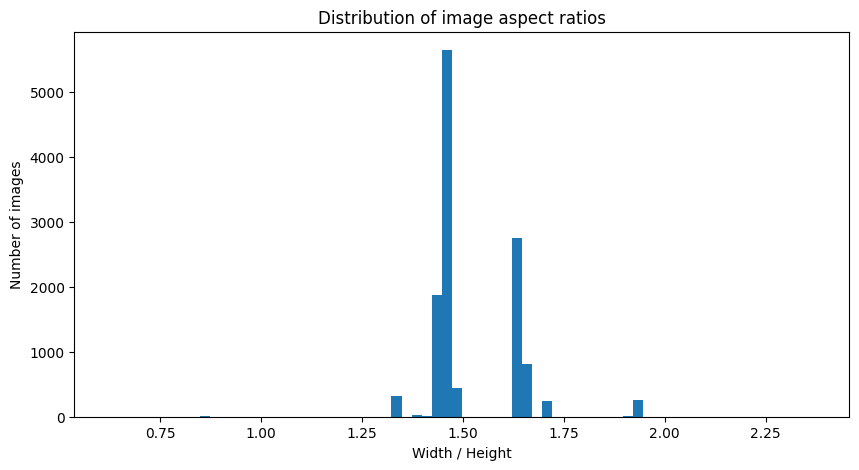

In [38]:
plt.figure(figsize=(10, 5))

plt.hist(
    image_info["aspect_ratio"],
    bins=70
)

plt.xlabel("Width / Height")
plt.ylabel("Number of images")
plt.title("Distribution of image aspect ratios")

plt.show()

In [ ]:
# 
image_info[
    ["min_pixel", "max_pixel", "mean_pixel", "std_pixel"]
].describe()

,min_pixel,max_pixel,mean_pixel,std_pixel
count,12400.000000,12400.000000,12400.000000,12400.000000
mean,0.025323,253.954516,44.714866,45.274125
std,0.706568,1.874185,17.552429,9.976874
min,0.000000,244.000000,5.268368,18.791117
25%,0.000000,254.000000,31.913272,38.444922
50%,0.000000,255.000000,42.087076,44.232712
75%,0.000000,255.000000,54.714507,50.757583
max,32.000000,255.000000,168.853278,106.943486


**NOTES** 🗒️  
1. two big groups of "ratios" so we won't tend to resize((224,224)) directly. It would deform the anatomy. so we'd keep the ration -> padding -> 224x224
2. we won't go with a dataset-speecific normalization

In [ ]:
display(image_info.head(3))

# Image_name without .png 
image_info["Image_name"] = image_info["image_name"].apply(lambda x: Path(x).stem)


,image_name,image_path,width,height,aspect_ratio,pil_mode,channels,shape,dtype,min_pixel,max_pixel,mean_pixel,std_pixel,Image_name
0,Patient00001_Plane1_10_of_15.png,C:\Users\malik\Documents\AI\my_prjects\fetal_a...,649,382,1.698953,RGBA,4,"(382, 649, 4)",uint8,0,255,80.370090,105.493106,Patient00001_Plane1_10_of_15
1,Patient00001_Plane1_11_of_15.png,C:\Users\malik\Documents\AI\my_prjects\fetal_a...,645,386,1.670984,RGBA,4,"(386, 645, 4)",uint8,0,255,98.215294,98.501262,Patient00001_Plane1_11_of_15
2,Patient00001_Plane1_12_of_15.png,C:\Users\malik\Documents\AI\my_prjects\fetal_a...,687,424,1.620283,RGBA,4,"(424, 687, 4)",uint8,0,255,95.621486,101.126645,Patient00001_Plane1_12_of_15


In [71]:
# is there a true link between image format and class ? CNN could use format, frame to learn rather than anatomie

eda_df = df_original.merge(
    image_info,
    on="Image_name",
    how="left",
    validate="one_to_one"
)

In [72]:
eda_df.head()

,Image_name,Patient_num,Plane,Brain_plane,Operator,US_Machine,Train,image_name,image_path,width,height,aspect_ratio,pil_mode,channels,shape,dtype,min_pixel,max_pixel,mean_pixel,std_pixel
0,Patient00001_Plane1_1_of_15,1,Other,Not A Brain,Other,Aloka,1,Patient00001_Plane1_1_of_15.png,C:\Users\malik\Documents\AI\my_prjects\fetal_a...,648,377,1.718833,RGBA,4,"(377, 648, 4)",uint8,0,255,74.581260,106.865348
1,Patient00001_Plane1_2_of_15,1,Other,Not A Brain,Other,Aloka,1,Patient00001_Plane1_2_of_15.png,C:\Users\malik\Documents\AI\my_prjects\fetal_a...,650,383,1.697128,RGBA,4,"(383, 650, 4)",uint8,0,255,74.451694,106.943486
2,Patient00001_Plane1_3_of_15,1,Other,Not A Brain,Other,Aloka,1,Patient00001_Plane1_3_of_15.png,C:\Users\malik\Documents\AI\my_prjects\fetal_a...,647,381,1.698163,L,1,"(381, 647)",uint8,0,255,20.490927,32.626611
3,Patient00001_Plane1_4_of_15,1,Other,Not A Brain,Other,Aloka,1,Patient00001_Plane1_4_of_15.png,C:\Users\malik\Documents\AI\my_prjects\fetal_a...,647,381,1.698163,L,1,"(381, 647)",uint8,0,255,43.591383,42.123377
4,Patient00001_Plane1_5_of_15,1,Other,Not A Brain,Other,Aloka,1,Patient00001_Plane1_5_of_15.png,C:\Users\malik\Documents\AI\my_prjects\fetal_a...,647,381,1.698163,L,1,"(381, 647)",uint8,0,255,34.615857,37.431003


In [ ]:
# little check
eda_df[
    ["width", "height", "aspect_ratio"]
].isna().sum()

width           0
height          0
aspect_ratio    0
dtype: int64

In [75]:
eda_df.groupby("Plane")["aspect_ratio"].describe()

,count,mean,std,min,25%,50%,75%,max
Plane,,,,,,,,
Fetal abdomen,711.0,1.509736,0.098439,1.444727,1.449472,1.450832,1.632653,2.169300
Fetal brain,3092.0,1.490878,0.082600,1.444727,1.449472,1.450832,1.450832,1.933468
Fetal femur,1040.0,1.510009,0.099381,1.444727,1.450832,1.450832,1.632653,1.933468
Fetal thorax,1718.0,1.542118,0.162666,1.444727,1.450832,1.450832,1.651786,2.169300
Maternal cervix,1626.0,1.441035,0.077056,1.163265,1.445923,1.450832,1.450832,2.039390
Other,4213.0,1.555359,0.110877,0.625000,1.450832,1.632653,1.632653,2.370180


interesting results that we'll keep in mind. maybe model would perform well (learn to classify "other" for instance) basing on the wrong reasons (format)

In [77]:
eda_df["resolution"] = (
    eda_df["width"].astype(str)
    + "x"
    + eda_df["height"].astype(str)
)

In [78]:
eda_df[["width", "height", "resolution"]].head()

,width,height,resolution
0,648,377,648x377
1,650,383,650x383
2,647,381,647x381
3,647,381,647x381
4,647,381,647x381


In [79]:
(
    eda_df
    .groupby(["Plane", "resolution"])
    .size()
    .groupby(level=0, group_keys=False)
    .nlargest(5)
)

Plane            resolution
Fetal abdomen    959x661        275
                 640x392        211
                 1137x787       129
                 961x663         87
                 1495x787         3
Fetal brain      959x661       1568
                 640x392        636
                 961x663        489
                 1137x787       373
                 1137x591         9
Fetal femur      959x661        484
                 640x392        292
                 961x663        135
                 1137x787       108
                 1137x591        10
Fetal thorax     959x661       1022
                 740x448        265
                 959x496        194
                 961x663        104
                 1137x787        95
Maternal cervix  959x661        750
                 869x601        191
                 745x559        173
                 961x663        145
                 640x392        139
Other            640x392       1426
                 740x448        538


In [81]:
resolution_by_class = pd.crosstab(
    eda_df["Plane"],
    eda_df["resolution"],
    normalize="index"
) * 100

In [83]:
resolution_by_class.head()

resolution,1007x714,1059x753,1059x755,1059x757,1063x676,1063x730,1063x747,1063x751,1109x787,1133x593,...,922x389,955x659,957x663,958x661,959x496,959x661,959x669,961x443,961x498,961x663
Plane,,,,,,,,,,,,,,,,,,,,,
Fetal abdomen,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.000000,0.281294,38.677918,0.000000,0.281294,0.000000,12.236287
Fetal brain,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.000000,0.161708,50.711514,0.000000,0.000000,0.064683,15.815006
Fetal femur,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.000000,0.096154,46.538462,0.000000,0.000000,0.288462,12.980769
Fetal thorax,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.000000,0.000000,0.000000,11.292200,59.487776,0.000000,0.058207,0.174622,6.053551
Maternal cervix,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.061501,0.061501,0.061501,0.000000,46.125461,0.061501,0.000000,0.000000,8.917589


In [82]:
for plane in resolution_by_class.index:
    print(f"\n{plane}")
    display(
        resolution_by_class.loc[plane]
        .sort_values(ascending=False)
        .head(5)
        .round(2)
        .to_frame("percentage")
    )


Fetal abdomen


,percentage
resolution,
959x661,38.68
640x392,29.68
1137x787,18.14
961x663,12.24
1495x787,0.42



Fetal brain


,percentage
resolution,
959x661,50.71
640x392,20.57
961x663,15.82
1137x787,12.06
1137x591,0.29



Fetal femur


,percentage
resolution,
959x661,46.54
640x392,28.08
961x663,12.98
1137x787,10.38
1137x591,0.96


... (2 outputs left out)


Maternal cervix


,percentage
resolution,
959x661,46.13
869x601,11.75
745x559,10.64
961x663,8.92
640x392,8.55



Other


,percentage
resolution,
640x392,33.85
740x448,12.77
959x661,12.68
1137x787,11.87
692x480,9.33


# EDA conclusions 🐙
- The dataset contains 12,400 ultrasound images from 1,792 patients across 6 classes.
- Class distribution is imbalanced, with Other strongly represented.
- Image resolutions vary, but a small number of formats dominate the dataset.
- Aspect ratios are mostly around ~1.45 and ~1.63, making direct square resizing potentially distortive.
- Resolution/aspect-ratio distributions differ across classes, suggesting a possible acquisition-format shortcut.
- Most images are grayscale; only 45 are RGBA, with no meaningful alpha transparency.
- Pixel intensity statistics are broadly consistent with dark-background ultrasound imagery.
- The official train/test split is patient-disjoint.